# WhatsApp assistant benchmark analysis
This notebook analyzes a real local capture of a Java rule-based assistant and Qwen2.5
on the same synthetic messages. The primary comparison uses all 108 unique messages at
concurrency 1. A fixed 24-message subset compares concurrency 1 and 2. Three repetitions
measure run-to-run behavior. The query is the sampling unit for confidence intervals.

In [1]:
from pathlib import Path
import sys
from IPython.display import Image, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "benchmark_config.json").is_file())
sys.path.insert(0, str(ROOT))
from src.process_data import BOOTSTRAPS, SEED, load_evaluation, paired_accuracy, summarize
from src.visualize import create_figures

display(f"Bootstrap seed: {SEED}. Resamples: {BOOTSTRAPS:,}.")

'Bootstrap seed: 42. Resamples: 2,000.'

## Ingestion and warm-up filtering
The runner labels warm-up before timing evaluation. We filter by this label, even if a
warm-up request happened to be fast. Errors in evaluation stay in the denominator for
accuracy and error rate. Successful requests define the displayed latency distribution.

In [2]:
raw, evaluation = load_evaluation(ROOT / "data/raw/test_run.jsonl")
display(raw.groupby(["phase", "concurrency", "system"]).size().rename("rows").to_frame())
display(f"Kept {len(evaluation)} of {len(raw)} timed attempts for evaluation.")

rows
phase      concurrency system          
evaluation 1           llm          324
                       rule_based   324
           2           llm           72
                       rule_based    72
warmup     1           llm            4
                       rule_based     4
           2           llm            4
                       rule_based     4

'Kept 792 of 808 timed attempts for evaluation.'

## Statistical aggregation
P95 is the 95th percentile of successful per-request durations. The 95% percentile
bootstrap samples query IDs with replacement and keeps all three repeats for each selected
query. The accuracy gain resamples paired query-level differences so both systems share the
same sampled queries. The one-sided exact McNemar test uses the first repeat and only
discordant pairs. The hypothesis test checks for improvement, while the interval is also
compared with the practical target of 10 percentage points.

In [3]:
import pandas as pd

summary = summarize(evaluation)
processed = ROOT / "data/processed/metrics_summary.csv"
processed.parent.mkdir(parents=True, exist_ok=True)
summary.to_csv(processed, index=False)
primary = summary.loc[summary["scope"].eq("primary")].set_index("system")
display(primary[["queries", "requests", "accuracy_pct", "accuracy_ci_low_pct",
                 "accuracy_ci_high_pct", "mean_ms", "median_ms", "p95_ms",
                 "errors", "error_rate_pct", "crm_correct", "crm_required",
                 "crm_completeness_pct"]].round(4))
comparison = paired_accuracy(evaluation)
display(pd.Series(comparison, name="value").to_frame())

,queries,requests,accuracy_pct,accuracy_ci_low_pct,accuracy_ci_high_pct,mean_ms,median_ms,p95_ms,errors,error_rate_pct,crm_correct,crm_required,crm_completeness_pct
system,,,,,,,,,,,,,
llm,108,324,38.8889,29.6296,48.1481,330.3954,323.3233,421.8178,9,2.7778,15,18,83.3333
rule_based,108,324,16.6667,10.1852,24.0741,0.0843,0.0615,0.1639,0,0.0000,0,18,0.0000


,value
paired_queries,108.000000
delta_pp,22.222222
ci_low_pp,8.333333
ci_high_pp,35.185185
first_repeat_llm_only,42.000000
first_repeat_baseline_only,18.000000
mcnemar_one_sided_p,0.001335


In [4]:
llm = primary.loc["llm"]
checks = pd.DataFrame([
    ("P95 latency (ms)", llm["p95_ms"], "≤ 5000", llm["p95_ms"] <= 5000),
    ("Request error rate (%)", llm["error_rate_pct"], "≤ 5", llm["error_rate_pct"] <= 5),
    ("Case-reference completeness (%)", llm["crm_completeness_pct"], "≥ 90",
     llm["crm_completeness_pct"] >= 90),
], columns=["guardrail", "observed", "target", "passes on this sample"])
display(checks.round(4))
display(f"LLM-only wins (first repeat): {comparison['first_repeat_llm_only']}")
display(f"Baseline-only wins (first repeat): {comparison['first_repeat_baseline_only']}")
display(f"One-sided p-value: {comparison['mcnemar_one_sided_p']:.3g}")
display(f"95% paired CI: {comparison['ci_low_pp']:.2f} to {comparison['ci_high_pp']:.2f} pp")
display(f"CRM field coverage: {int(llm['crm_correct'])}/{int(llm['crm_required'])} attempts "
      "across six unique annotated messages.")

,guardrail,observed,target,passes on this sample
0,P95 latency (ms),421.8178,≤ 5000,True
1,Request error rate (%),2.7778,≤ 5,True
2,Case-reference completeness (%),83.3333,≥ 90,False


'LLM-only wins (first repeat): 42'

'Baseline-only wins (first repeat): 18'

'One-sided p-value: 0.00134'

'95% paired CI: 8.33 to 35.19 pp'

'CRM field coverage: 15/18 attempts across six unique annotated messages.'

## Scientific figures
The load figure holds the query subset fixed at both load levels. Error bars show 95%
intervals for the median. The box plot shows the observed Q1–Q3 spread, conventional
1.5 × IQR whiskers and a separate median interval. Both use log-scaled latency axes
because the systems differ by orders of magnitude. Each plot is exported as vector PDF
and as a 300 DPI PNG.

'fig1_latency_vs_load.png'

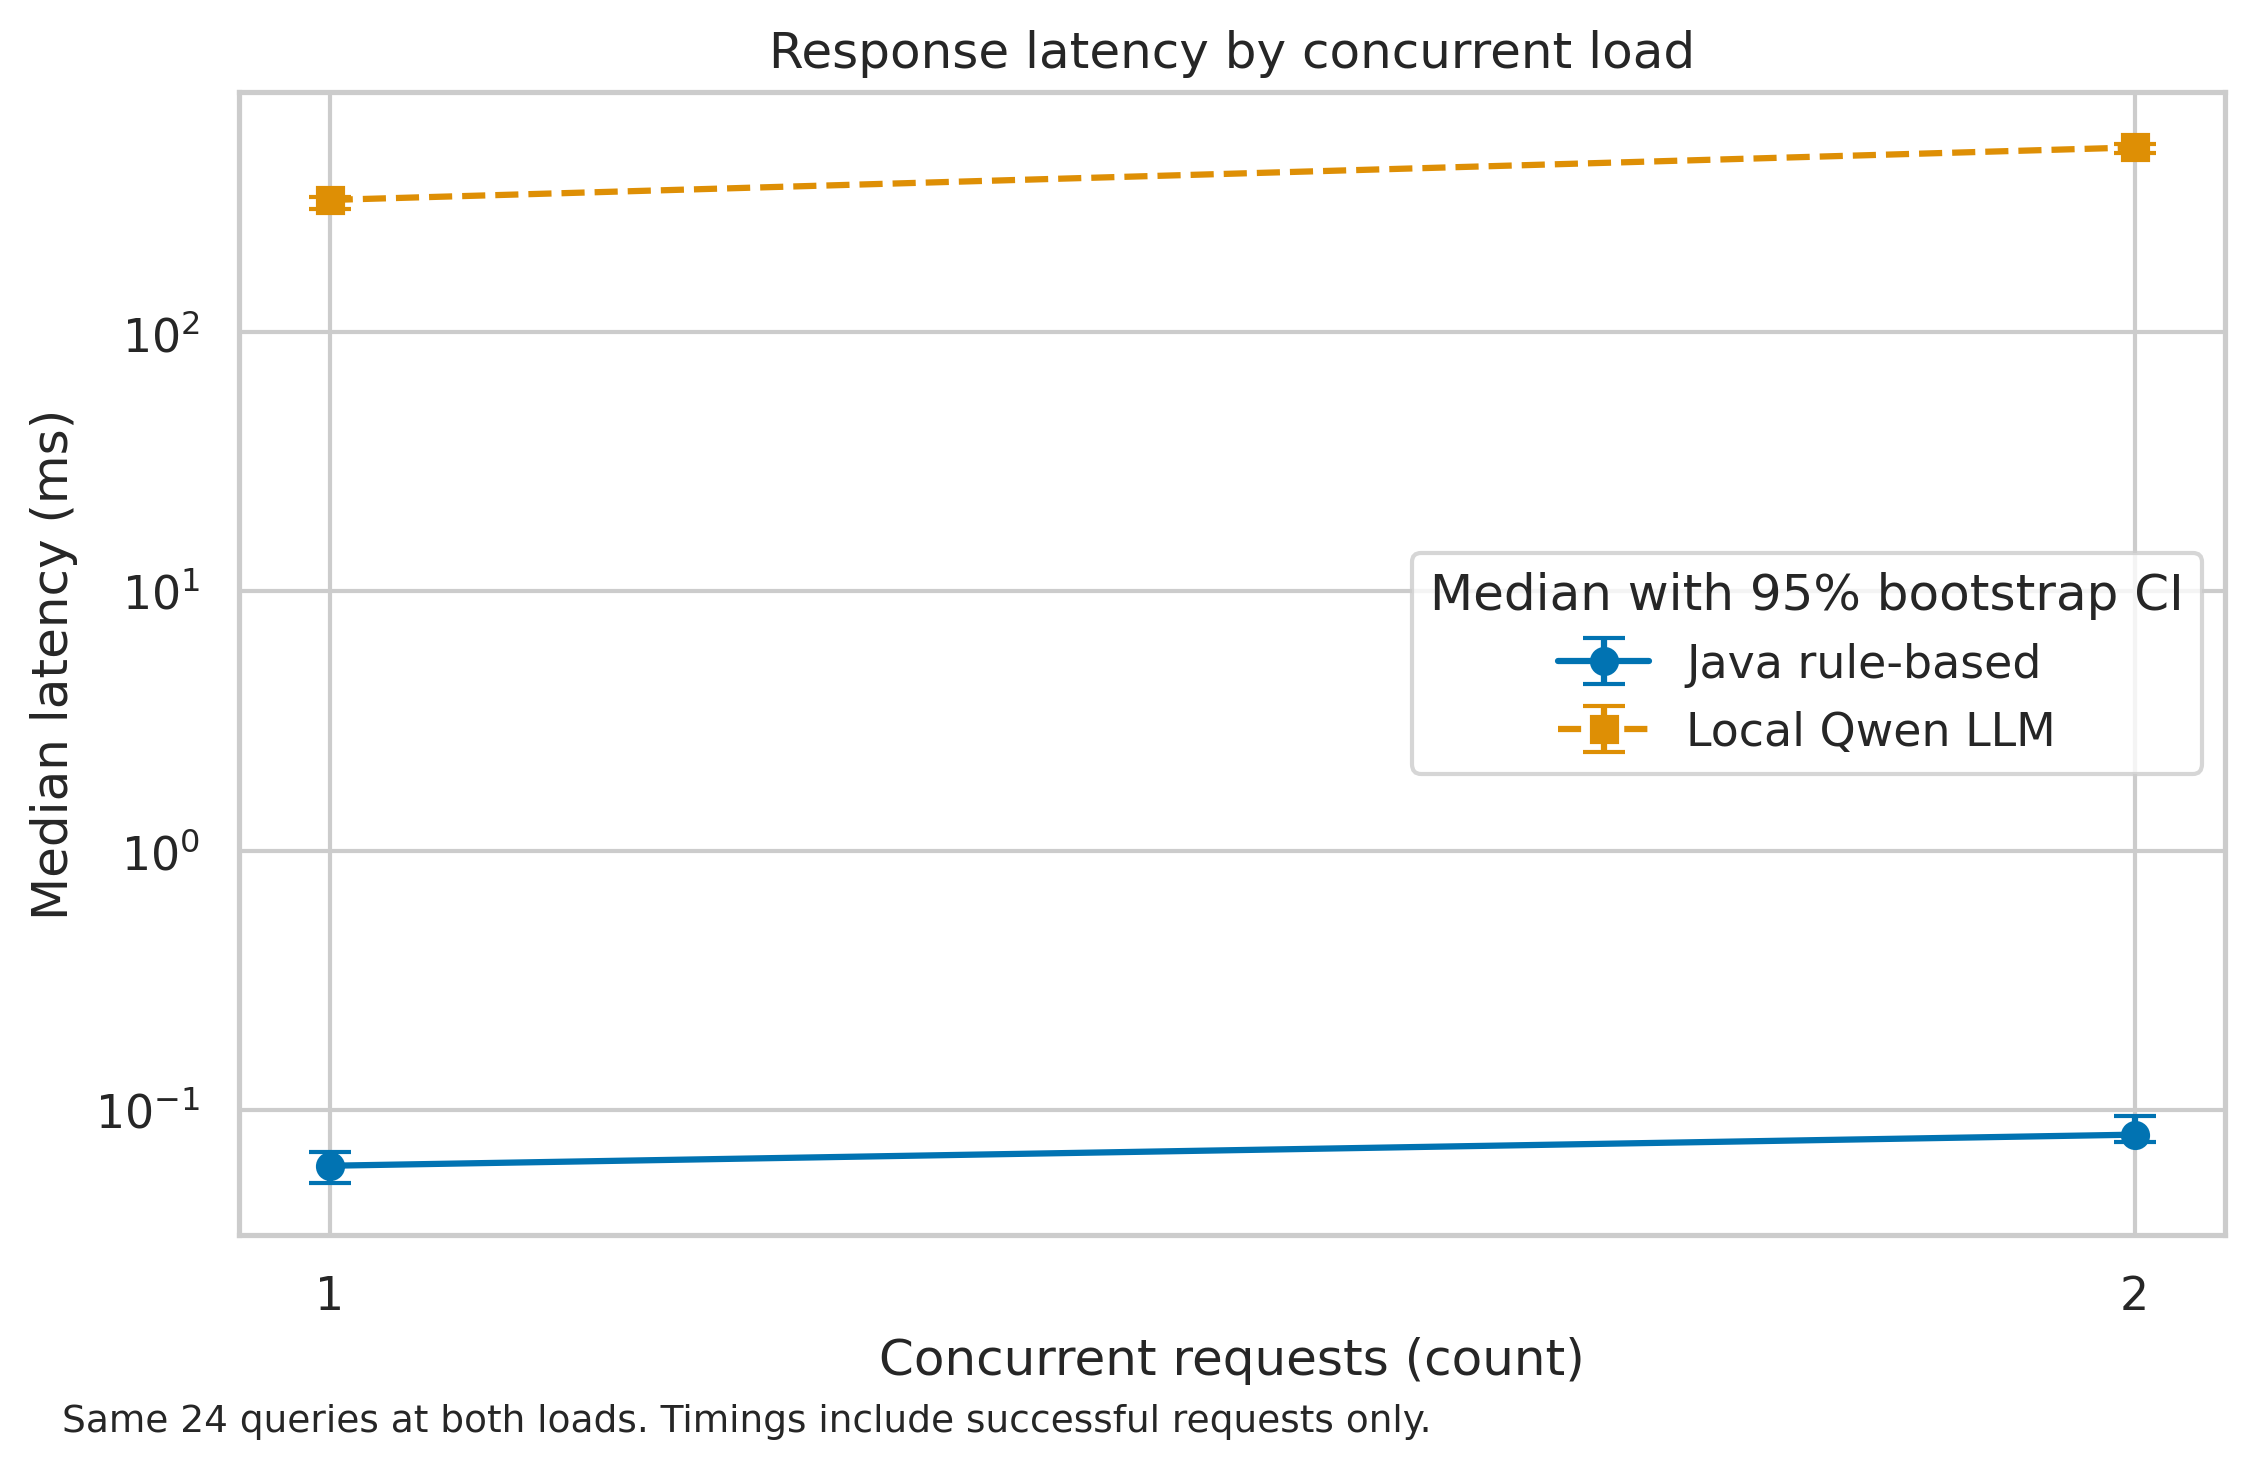

'fig2_distribution_boxplot.png'

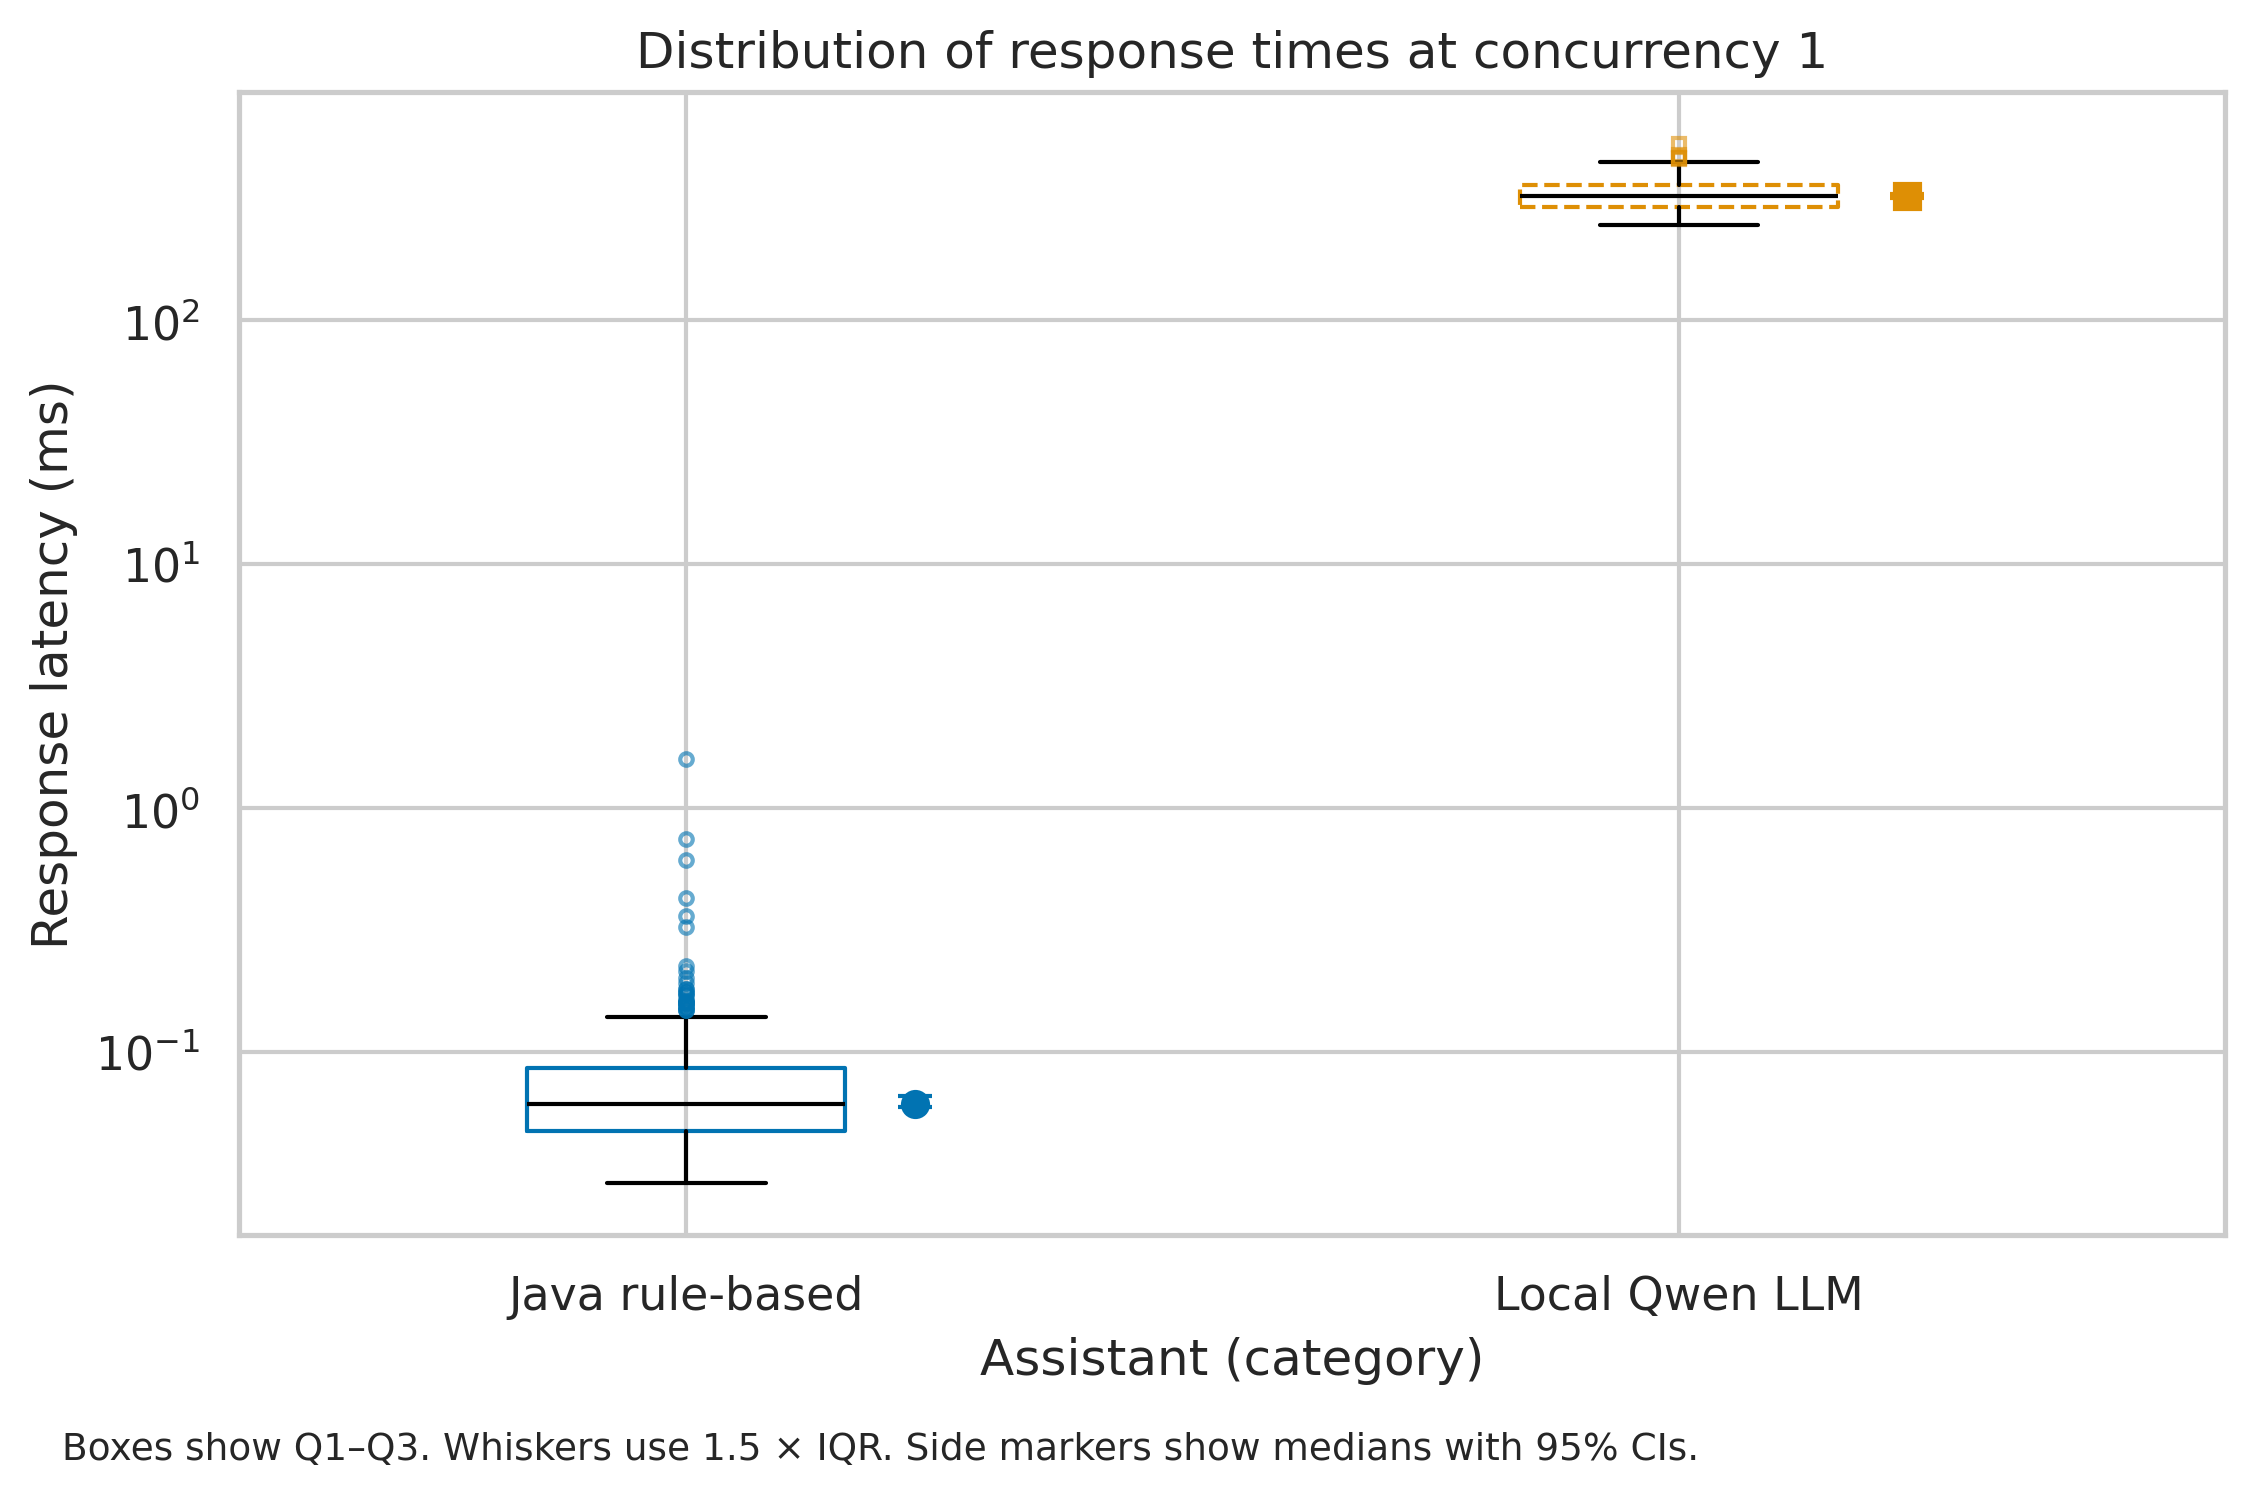

In [5]:
figure_paths = create_figures(evaluation, summary, ROOT / "reports/figures")
for image_path in figure_paths:
    display(image_path.name)
    display(Image(filename=str(image_path), width=740))

## Limits of interpretation
Labels are manually assigned to balanced synthetic queries and cover three languages.
Timing describes this local CPU setup, including Java IPC versus localhost HTTP and model
inference. Real WhatsApp transport and CRM writes are outside the measured path. The
CRM metric checks one ticket-reference field on six unique eligible messages, and reply
quality was not evaluated. The load experiment covers concurrency 1 and 2.